MCS 320 Quiz 8 Friday 23 October 2026

# Question 1

Let $f(x, y, z) = x z^2 - y^3 + 3 y z + 1 = 0$.

Compute the points on the surface defined by $f$ closest to the origin.

## answer to question 1

In [1]:
f(x, y, z) = x*z^2 - y^3 + 3*y*z + 1
f

(x, y, z) |--> -y^3 + x*z^2 + 3*y*z + 1

Closest to the origin implies that we minimize the squared distance to the origin, represented by the target below.

In [2]:
target(x, y, z) = x^2 + y^2 + z^2
target

(x, y, z) |--> x^2 + y^2 + z^2

To setup the system with Lagrange multipliers, we compute the gradients.

In [3]:
gf = f.diff()
gf

(x, y, z) |--> (z^2, -3*y^2 + 3*z, 2*x*z + 3*y)

In [4]:
gt = target.diff()
gt

(x, y, z) |--> (2*x, 2*y, 2*z)

In [5]:
Lambda = var('Lambda')
eqs = [gt(x, y, z)[k] - Lambda*gf(x, y, z)[k] for k in range(3)]
eqs.append(f(x,y,z))
eqs

[-Lambda*z^2 + 2*x,
 3*(y^2 - z)*Lambda + 2*y,
 -(2*x*z + 3*y)*Lambda + 2*z,
 -y^3 + x*z^2 + 3*y*z + 1]

In [6]:
s = solve(eqs, (x, y, z, Lambda), solution_dict=True)
s

[{x: 0.09851801905253889 + 0.41947290160707956*I,
  y: -0.15186084909915412 + 1.870565605348413*I,
  z: -1.2576374291642396 + 0.030307654408152983*I,
  Lambda: 0.09882370178700539 + 0.5354978687788915*I},
 {x: 0.09851801905254044 - 0.41947290160707784*I,
  y: -0.15186084909915382 - 1.870565605348413*I,
  z: -1.2576374291642392 - 0.030307654408153837*I,
  Lambda: 0.09882370178700539 - 0.5354978687788915*I},
 {x: -0.04935617512036726,
  y: 0.5874883286647993,
  z: -0.44675046282763325,
  Lambda: -0.49458563535911604},
 {x: -0.1839591201955121,
  y: -0.5049562682215744,
  z: 0.6876880805966243,
  Lambda: -0.777979745520644},
 {x: -0.07517670299717875 - 0.08703258174592049*I,
  y: 0.009140433289586775 + 0.5973292712652615*I,
  z: -0.14902910475199982 + 0.565516824735201*I,
  Lambda: 0.6333298581123574 + 0.2261865418907127*I},
 {x: -0.07517670299717985 + 0.0870325817459198*I,
  y: 0.009140433289586778 - 0.5973292712652616*I,
  z: -0.14902910475199987 - 0.5655168247352012*I,
  Lambda: 0.6333

To find the closest point, we evaluate the coordinates of the solutions at the target.

In [7]:
sqd = [target(sol[x], sol[y], sol[z]) for sol in s]
for d in sqd:
    print('distance^2 :', d)

distance^2 : -2.0614723322088717 - 0.5617121647704019*I
distance^2 : -2.061472332208871 + 0.5617121647704022*I
distance^2 : 0.5471645443765761
distance^2 : 0.7617366869140347
distance^2 : -0.6562414493968028 - 0.14455159041514448*I
distance^2 : -0.6562414493968028 + 0.14455159041514445*I
distance^2 : -3.766471393241972 - 4.096447392415686*I
distance^2 : -3.7664713932419724 + 4.096447392415687*I
distance^2 : -1.0590080463858045 - 2.3922089505244966*I
distance^2 : -1.059008046385804 + 2.3922089505244974*I
distance^2 : 8.313688079201313
distance^2 : -2.7035346574790404 + 0.4956178366388875*I
distance^2 : -2.7035346574790418 - 0.49561783663888903*I
distance^2 : 3.693497905192853 - 2.54697637550192*I
distance^2 : 3.693497905192853 + 2.5469763755019192*I


The point at index 2 is the closest point.  To select it properly, we move to the complex absolute value distance metric.

In [8]:
rd = [abs(x.real()) + abs(x.imag()) for x in sqd]
rd

[2.6231844969792735,
 2.623184496979273,
 0.5471645443765761,
 0.7617366869140347,
 0.8007930398119474,
 0.8007930398119473,
 7.862918785657659,
 7.8629187856576594,
 3.451216996910301,
 3.4512169969103015,
 8.313688079201313,
 3.1991524941179277,
 3.199152494117931,
 6.240474280694773,
 6.240474280694772]

In [9]:
idx = rd.index(min(rd))
idx

2

Then the coordinates of the closest point are below.

In [10]:
s[idx]

{x: -0.04935617512036726,
 y: 0.5874883286647993,
 z: -0.44675046282763325,
 Lambda: -0.49458563535911604}

# Question 2

Consider the curve defined by
$$
   4 \left( x^2 + (y+1)^2 - 1 \right)^2 + (y^2 - x^2)(y+1) = 0.
$$

1. Plot the curve for a suitable range of $x$ and $y$.

2. Transform into polar coordinates and plot.

3. Describe the differences between the two plots.

## answer to question 2

In [11]:
reset()

In [12]:
x, y = var('x, y')
curve = 4*(x^2 + (y+1)^2 - 1)^2 + (y^2 - x^2)*(y+1)
show(curve)

4*(x^2 + (y + 1)^2 - 1)^2 - (x^2 - y^2)*(y + 1)

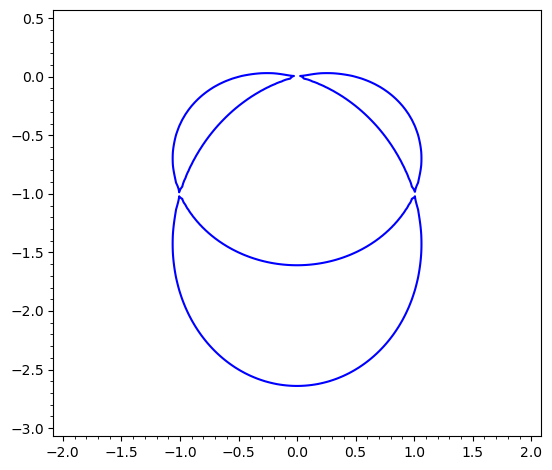

In [13]:
implicit_plot(curve, (x, -2, 2), (y, -3 ,0.5))

In [14]:
r, t = var('r, t')
rt = curve(x=r*cos(t), y=r*sin(t))
show(rt)

4*(r^2*cos(t)^2 + (r*sin(t) + 1)^2 - 1)^2 - (r^2*cos(t)^2 - r^2*sin(t)^2)*(r*sin(t) + 1)

In [15]:
s = solve(rt, r)
show(s)

[r == -1/8*(15*cos(t)^2*sin(t) + 17*sin(t)^3 - sqrt(16*cos(t)^2 + 17*sin(t)^2)*(cos(t)^2 - sin(t)^2))/(cos(t)^4 + 2*cos(t)^2*sin(t)^2 + sin(t)^4), r == -1/8*(15*cos(t)^2*sin(t) + 17*sin(t)^3 + sqrt(16*cos(t)^2 + 17*sin(t)^2)*(cos(t)^2 - sin(t)^2))/(cos(t)^4 + 2*cos(t)^2*sin(t)^2 + sin(t)^4), r == 0]

In [16]:
r0 = s[0].rhs().trig_simplify()
show(r0)

1/8*(2*cos(t)^2 - 17)*sin(t) + 1/8*(2*cos(t)^2 - 1)*sqrt(-cos(t)^2 + 17)

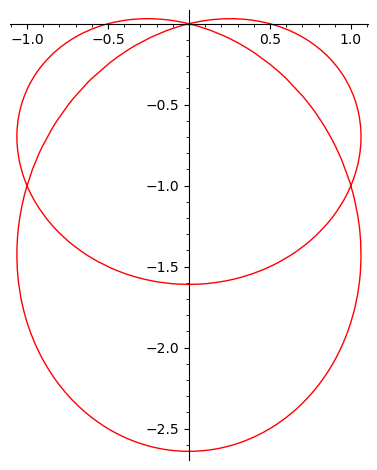

In [17]:
p1 = polar_plot(r0, (t, 0, 2*pi), color='red')
p1.show()

One of the branches factors out in polar coordinates.  The plot in polar coordinates does not require a suitable choice of a window for $x$- and $y$-coordinates.  In rectangular coordinates, we see white spots where the curve intersects itself, indicating difficulties at computing those singularities.